In [1]:
# 导入 Gymnasium 环境库（新版 gym，替代旧版 gym）
import gymnasium as gym
# 导入 PyTorch，用于张量运算、Softmax 和概率采样
import torch
# 导入 Matplotlib，用于绘制奖励曲线
import matplotlib.pyplot as plt

# 创建 CartPole-v1 环境（v1 最大步数 500，v0 是 200）
env = gym.make('CartPole-v1')

# 状态维度：4（小车位置、小车速度、杆子角度、杆子角速度）
n_state = env.observation_space.shape[0]
# 动作数量：2（0=向左推，1=向右推）
n_action = env.action_space.n


def run_episode(env, weight):
    """
    用给定的权重矩阵跑完一个完整的 episode，同时记录每一步的策略梯度。

    策略：state → softmax → 概率分布 → 伯努利采样动作。
    这是一个随机策略（stochastic policy），不是 argmax 确定性选择。

    参数:
        env: Gymnasium 环境
        weight: 形状为 (n_state, n_action) 的权重矩阵

    返回:
        total_reward: 该 episode 的累计奖励
        grads: 每一步的 log-policy 梯度列表，形状均为 (n_state, n_action)
    """
    # 重置环境，获取初始状态（新版 gymnasium 返回两个值）
    state, info = env.reset()
    grads = []          # 记录每一步的梯度
    total_reward = 0
    terminated = False  # 任务是否自然结束（杆倒了 / 车出界）
    truncated = False   # 是否因达到最大步数而截断

    while not (terminated or truncated):
        # 将 numpy 数组转为 PyTorch 浮点张量
        state = torch.from_numpy(state).float()

        # 线性映射：state(4,) × weight(4,2) → z(2,)
        z = torch.matmul(state, weight) # z：策略网络的输出，也叫 logits

        # Softmax 将 logits 转为动作概率分布
        probs = torch.nn.Softmax(dim=0)(z)

        # 伯努利采样：以 probs[1] 的概率选择动作 1，否则选动作 0
        # 这样策略是随机的，有利于探索
        action = int(torch.bernoulli(probs[1]).item())

        # ===== 手动推导策略梯度（REINFORCE 的核心）=====
        # 对 softmax 输出求导：d_softmax[i][j] = diag(probs) - probs ⊗ probs^T
        d_softmax = torch.diag(probs) - probs.view(-1, 1) * probs

        # 对 log π(a|s) 求导：∂logπ(a)/∂z = d_softmax[a] / probs[a]
        d_log = d_softmax[action] / probs[action]

        # 链式法则：∂logπ(a)/∂weight = state^T ⊗ d_log
        # 外积形式：grad = state(4,1) × d_log(1,2) → (4,2)
        grad = state.view(-1, 1) * d_log
        grads.append(grad)

        # 执行动作（新版 gymnasium step 返回 5 个值）
        state, reward, terminated, truncated, info = env.step(action)
        total_reward += reward

    return total_reward, grads


Episode 1: 52.0
Episode 2: 31.0
Episode 3: 36.0
Episode 4: 26.0
Episode 5: 31.0
Episode 6: 104.0
Episode 7: 29.0
Episode 8: 37.0
Episode 9: 30.0
Episode 10: 48.0
Episode 11: 47.0
Episode 12: 66.0
Episode 13: 43.0
Episode 14: 94.0
Episode 15: 164.0
Episode 16: 40.0
Episode 17: 88.0
Episode 18: 44.0
Episode 19: 42.0
Episode 20: 30.0
Episode 21: 36.0
Episode 22: 29.0
Episode 23: 55.0
Episode 24: 124.0
Episode 25: 88.0
Episode 26: 42.0
Episode 27: 69.0
Episode 28: 50.0
Episode 29: 44.0
Episode 30: 150.0
Episode 31: 131.0
Episode 32: 16.0
Episode 33: 35.0
Episode 34: 161.0
Episode 35: 27.0
Episode 36: 128.0
Episode 37: 117.0
Episode 38: 70.0
Episode 39: 156.0
Episode 40: 150.0
Episode 41: 176.0
Episode 42: 82.0
Episode 43: 56.0
Episode 44: 149.0
Episode 45: 113.0
Episode 46: 244.0
Episode 47: 216.0
Episode 48: 326.0
Episode 49: 85.0
Episode 50: 151.0
Episode 51: 83.0
Episode 52: 211.0
Episode 53: 119.0
Episode 54: 86.0
Episode 55: 149.0
Episode 56: 299.0
Episode 57: 97.0
Episode 58: 222.0
E

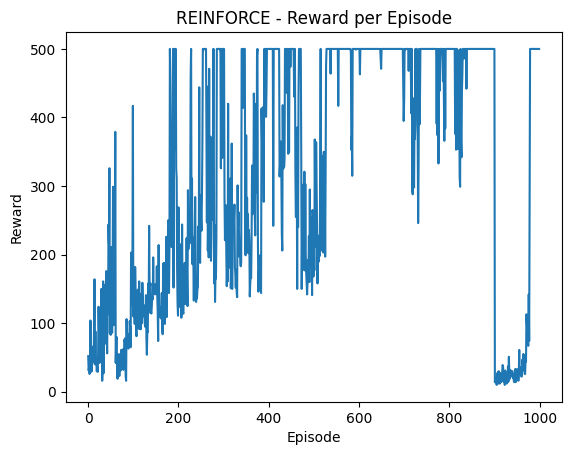

In [2]:
# ==================== 第一部分：REINFORCE 训练 ====================

n_episode = 1000
learning_rate = 0.001  # 学习率，控制每次梯度更新的步长

total_rewards = []     # 记录每轮奖励

# 初始随机权重 weight：shape [4,2]，就是咱们一直说的4×2矩阵
weight = torch.rand(n_state, n_action)

# 循环：一局一局训练
for episode in range(n_episode):
    # ---------------------- 第一步：跑完整一局，收集整条轨迹信息 ----------------------
    # run_episode里面会：
    # 一步一步和环境交互，每一步手动算出梯度，存进grads列表
    # 【重点：这里跑的时候，weight全程不动！只是收集本局每一步的梯度】
    total_reward, gradients = run_episode(env, weight)
    print(f'Episode {episode + 1}: {total_reward}')

    # ---------------------- 第二步：一局跑完了！现在才开始更新weight（蒙特卡洛特征） ----------------------
    # gradients 是一个列表：里面存了本局每一步对应的梯度，gradients[0]是第0步梯度，gradients[1]第1步...
    # i 代表这一步是本局里面的第i步
    for i, gradient in enumerate(gradients):
        # total_reward - i 就是这个代码里面的 G_t！
        # CartPole每一步奖励都是+1
        # 假设本局一共拿了120分（total_reward=120）
        # i=0（第0步）：G = 120 - 0 = 120
        # i=1（第1步）：G = 120 - 1 = 119
        # i=2（第2步）：G = 120 - 2 = 118
        # ...
        # 含义：从第i这一步往后，还能拿到多少奖励
        G_t = total_reward - i
        weight += learning_rate * gradient * G_t

    # 把本局总分存起来，后面画图
    total_rewards.append(total_reward)


print(
    f'Average total reward over {n_episode} episode: '
    f'{sum(total_rewards) / n_episode:.2f}'
)

# 绘制训练过程中的奖励曲线
plt.plot(total_rewards)
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.title('REINFORCE - Reward per Episode')
plt.show()


In [3]:
# ==================== 第二部分：用训练好的权重评估 ====================

n_episode_eval = 100
total_rewards_eval = []

for episode in range(n_episode_eval):
    # 评估时不再收集梯度，只关心奖励
    total_reward, _ = run_episode(env, weight)
    print(f'Episode {episode + 1}: {total_reward}')
    total_rewards_eval.append(total_reward)

print(
    f'Average total reward over {n_episode_eval} eval episode: '
    f'{sum(total_rewards_eval) / n_episode_eval:.2f}'
)

Episode 1: 500.0
Episode 2: 500.0
Episode 3: 500.0
Episode 4: 500.0
Episode 5: 500.0
Episode 6: 500.0
Episode 7: 500.0
Episode 8: 500.0
Episode 9: 500.0
Episode 10: 500.0
Episode 11: 500.0
Episode 12: 500.0
Episode 13: 500.0
Episode 14: 500.0
Episode 15: 500.0
Episode 16: 500.0
Episode 17: 500.0
Episode 18: 500.0
Episode 19: 500.0
Episode 20: 500.0
Episode 21: 500.0
Episode 22: 500.0
Episode 23: 500.0
Episode 24: 500.0
Episode 25: 500.0
Episode 26: 500.0
Episode 27: 500.0
Episode 28: 500.0
Episode 29: 500.0
Episode 30: 500.0
Episode 31: 500.0
Episode 32: 500.0
Episode 33: 500.0
Episode 34: 500.0
Episode 35: 500.0
Episode 36: 500.0
Episode 37: 500.0
Episode 38: 500.0
Episode 39: 500.0
Episode 40: 500.0
Episode 41: 500.0
Episode 42: 500.0
Episode 43: 500.0
Episode 44: 500.0
Episode 45: 500.0
Episode 46: 500.0
Episode 47: 500.0
Episode 48: 500.0
Episode 49: 500.0
Episode 50: 500.0
Episode 51: 500.0
Episode 52: 500.0
Episode 53: 500.0
Episode 54: 500.0
Episode 55: 500.0
Episode 56: 500.0
E